In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
DATA_DIR = "/content/drive/MyDrive/Data Science projects/archive (2).zip"

In [ ]:
import zipfile

# Open the zip file in read mode
with zipfile.ZipFile(DATA_DIR, 'r') as zip_ref:
    # List all the contents of the zip file
    print("Contents of the zip file:")
    for file_name in zip_ref.namelist():
        print(file_name)

Contents of the zip file:
bloodcells_dataset/basophil/BA_100102.jpg
bloodcells_dataset/basophil/BA_101381.jpg
bloodcells_dataset/basophil/BA_101611.jpg
bloodcells_dataset/basophil/BA_102039.jpg
bloodcells_dataset/basophil/BA_102750.jpg
bloodcells_dataset/basophil/BA_10387.jpg
bloodcells_dataset/basophil/BA_10622.jpg
bloodcells_dataset/basophil/BA_107595.jpg
bloodcells_dataset/basophil/BA_107876.jpg
bloodcells_dataset/basophil/BA_111710.jpg
bloodcells_dataset/basophil/BA_112418.jpg
bloodcells_dataset/basophil/BA_114542.jpg
bloodcells_dataset/basophil/BA_114899.jpg
bloodcells_dataset/basophil/BA_115323.jpg
bloodcells_dataset/basophil/BA_115777.jpg
bloodcells_dataset/basophil/BA_116477.jpg
bloodcells_dataset/basophil/BA_119131.jpg
bloodcells_dataset/basophil/BA_119883.jpg
bloodcells_dataset/basophil/BA_120278.jpg
bloodcells_dataset/basophil/BA_120688.jpg
bloodcells_dataset/basophil/BA_121453.jpg
bloodcells_dataset/basophil/BA_121897.jpg
bloodcells_dataset/basophil/BA_1223.jpg
bloodcells_d

In [ ]:
import zipfile
import os

# Define the directory where the files will be extracted
EXTRACT_DIR = "/content/extracted_bloodcells"

# Create the extraction directory if it doesn't exist
os.makedirs(EXTRACT_DIR, exist_ok=True)

# Open the zip file and extract all its contents
with zipfile.ZipFile(DATA_DIR, 'r') as zip_ref:
    print(f"Extracting files to {EXTRACT_DIR}...")
    zip_ref.extractall(EXTRACT_DIR)
    print("Extraction complete.")

# Verify the contents of the extracted directory (optional)
print("Contents of the extracted directory:")
print(os.listdir(EXTRACT_DIR))

Extracting files to /content/extracted_bloodcells...
Extraction complete.
Contents of the extracted directory:
['bloodcells_dataset']


In [ ]:
import os

print(os.listdir(EXTRACT_DIR))

['bloodcells_dataset']


In [ ]:
DATA_DIR = os.path.join(EXTRACT_DIR, "bloodcells_dataset")

print(DATA_DIR)
print(os.listdir(DATA_DIR))

/content/extracted_bloodcells/bloodcells_dataset
['erythroblast', 'platelet', 'neutrophil', 'monocyte', 'ig', 'basophil', 'lymphocyte', 'eosinophil']


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight


In [ ]:
DATA_DIR = 'bloodcells_dataset'
img_size = 128
batch_size = 32

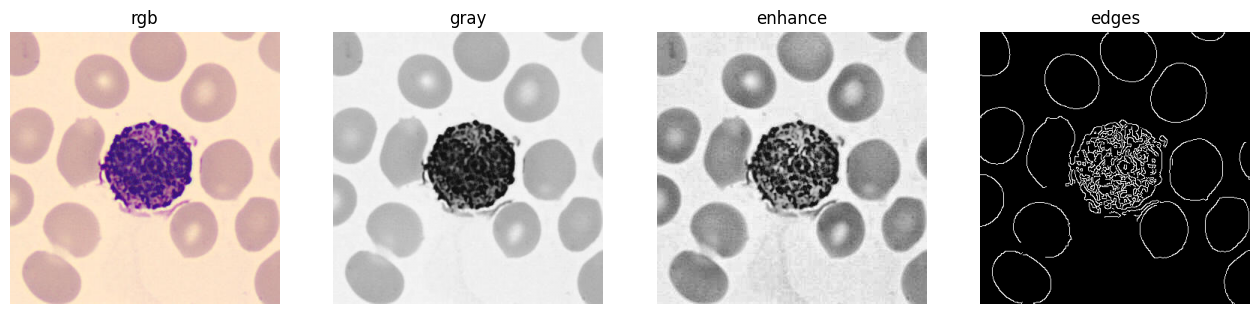

<Figure size 640x480 with 0 Axes>

In [ ]:
DATA_DIR = os.path.join(EXTRACT_DIR, "bloodcells_dataset")

sample_class = 'basophil'
sample_file = os.listdir(f'{DATA_DIR}/{sample_class}')[0]
sample_path = f'{DATA_DIR}/{sample_class}/{sample_file}'

bgr = cv2.imread(sample_path)
rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
clahe = cv2.createCLAHE(clipLimit = 3.0 , tileGridSize = (8,8))
enhance = clahe.apply(gray)
edges = cv2.Canny(gray, 50 ,150)

fig, axes = plt.subplots(1,4,figsize = (16,4))
axes[0].imshow(rgb) ; axes[0].set_title('rgb')
axes[1].imshow(gray, cmap = 'gray'); axes[1].set_title('gray')
axes[2].imshow(enhance , cmap = 'gray') ; axes[2].set_title('enhance')
axes[3].imshow(edges, cmap = 'gray') ; axes[3].set_title('edges')
for ax in axes: ax.axis('off')
plt.show()
plt.tight_layout()

In [ ]:
train = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR, validation_split = 0.2 , subset = 'training' , seed = 43,
    image_size = (img_size , img_size), batch_size = batch_size
)


val_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR , validation_split = 0.3 , subset = 'validation', seed = 42,
    image_size = (img_size,img_size), batch_size = batch_size
)

class_name = train.class_names
print(class_name)

Found 17092 files belonging to 8 classes.
Using 13674 files for training.
Found 17092 files belonging to 8 classes.
Using 5127 files for validation.
['basophil', 'eosinophil', 'erythroblast', 'ig', 'lymphocyte', 'monocyte', 'neutrophil', 'platelet']


In [ ]:
class_counts = [len(os.listdir(f'{DATA_DIR}/{c}')) for c in class_name]
labels_flat = np.concatenate([[i]* count for i , count in enumerate(class_counts)])
weights = compute_class_weight('balanced' , classes = np.arange(len(class_name)) , y = labels_flat)

class_weight_dict = dict(enumerate(weights))

print('high weighs to rare class', class_weight_dict)

data_aug = tf.keras.Sequential([
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.4),
    layers.RandomZoom(0.2),

])

auto = tf.data.AUTOTUNE
train = train.cache().shuffle(777).prefetch(buffer_size = auto)
val_ds = val_ds.cache().shuffle(888).prefetch(buffer_size = auto)

num =  len(class_name)

high weighs to rare class {0: np.float64(1.7541050903119868), 1: np.float64(0.6854347128649342), 2: np.float64(1.377498388136686), 3: np.float64(0.7379965457685665), 4: np.float64(1.7598846787479407), 5: np.float64(1.5045774647887324), 6: np.float64(0.6417843196155002), 7: np.float64(0.909923339011925)}


In [ ]:


model =  tf.keras.models.Sequential([
    tf.keras.layers.Input(shape = (img_size , img_size ,3)),
    data_aug,
    tf.keras.layers.Rescaling(1./255),

    tf.keras.layers.Conv2D(64, 3, padding = 'same' , activation = 'relu'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(128 , 3, padding = 'same', activation = 'relu'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dropout(0.4),
    tf.keras.layers.Dense(num , activation = 'softmax')
])


model.compile( optimizer = 'adam' , loss = 'sparse_categorical_crossentropy' ,metrics = ['accuracy'] )
model.summary()

history = model.fit(
    train , validation_data = val_ds , epochs = 5 ,
    class_weight = class_weight_dict ,
    callbacks = [tf.keras.callbacks.EarlyStopping(monitor = 'val_accuracy' , patience = 3, restore_best_weights = True)]
)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 8)              │         1,032 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 77,448 (302.53 KB)

 Trainable params: 77,064 (301.03 KB)

 Non-trainable params: 384 (1.50 KB)

Epoch 1/5
337/428 ━━━━━━━━━━━━━━━━━━━━ 5:13 3s/step - accuracy: 0.4358 - loss: 1.6181

KeyboardInterrupt: 

In [ ]:
base_model = MobileNetV2(input_shape = (img_size , img_size ,3), include_top = False , weights = 'imagenet')

base_model.trainable=False

transfer_model =models.Sequential([
    layers.Input(shape = (img_size, img_size , 3)),
    data_aug ,
    layers.Rescaling(1./255, offset = -1),
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.4),
    layers.Dense(num , activation = 'softmax')

])

transfer_model.compile(optimizer = 'adam' , loss= 'sparse_categorical_crossentropy' , metrics = ['accuracy'])

transfer_history = transfer_model.fit(
    train, validation_data = val_ds , epochs = 5,
    class_weight = class_weight_dict,
    callbacks = [tf.keras.callbacks.EarlyStopping(monitor = 'val_accuracy' , patience = 3 , restore_best_weights = True)]

)



In [ ]:
def eval(model , val_ds , class_name, title, save_path):
  y_true,y_pred = [],[]
  for images, labels in val_ds:
    pred = model.predict(images, verbose = 0 )
    y_pred.extend(np.argmax(pred, axis = 1))
    y_true.extend(labels.numpy())

  print(classification_report(y_pred, y_true, target = class_name))
  confuse = confusion_matrix(y_true, y_pred)
  plt.figure(figsize = (10,8))
  sns.heatmap(confuse, annot = True, fmt='d', cmap = 'Gold')
  plt.title(title);plt.xlabel('predicts') ;plt.ylabel('actual');plt.xtics(rotation = 90)
  plt.tight_layout()
  plt.show()
  plt.savefig()

  evaluate_model(model, val_ds, class_name)
  evaluate_model(transfer_model, val_ds, class_name)

  model.save('bloodcells_customized')
  transfer_model.save('bloodcells_mobilenetv2')
  print('finally done dhana done done')